### 1. Data loading and overview


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 80)
sns.set_theme(style="whitegrid")

In [4]:
PATH = "../../Data/raw/airline_reviews.csv"
df = pd.read_csv(PATH, encoding="utf-8-sig")
df.shape

C:\Users\MSI\AppData\Local\Temp\ipykernel_30092\139314019.py:2: DtypeWarning: Columns (14: transit_city, 15: transit_airport) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(PATH, encoding="utf-8-sig")


(156323, 25)

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 156323 entries, 0 to 156322
Data columns (total 25 columns):
 #   Column                  Non-Null Count   Dtype  
---  ------                  --------------   -----  
 0   review_id               156323 non-null  int64  
 1   airline_id              156323 non-null  int64  
 2   verify                  156323 non-null  int64  
 3   date_submitted          156323 non-null  str    
 4   date_flown              116716 non-null  str    
 5   customer_name           156322 non-null  str    
 6   nationality             155241 non-null  str    
 7   type_of_traveller       116877 non-null  str    
 8   seat_type               153299 non-null  str    
 9   aircraft                41229 non-null   str    
 10  origin_city             116410 non-null  str    
 11  origin_airport          76023 non-null   str    
 12  destination_city        116169 non-null  str    
 13  destination_airport     73598 non-null   str    
 14  transit_city            30105 n

In [6]:
df.sample(5, random_state=42)

,review_id,airline_id,verify,date_submitted,date_flown,customer_name,nationality,type_of_traveller,seat_type,aircraft,origin_city,origin_airport,destination_city,destination_airport,transit_city,transit_airport,seat_comfort,cabin_staff_service,food_and_beverages,inflight_entertainment,ground_service,wifi_and_connectivity,value_for_money,recommended,review
36203,36204,507,0,2015-02-24,NaN,Thomas Rodriguez 7,Portugal,NaN,Economy Class,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3.0,5.0,5.0,NaN,NaN,NaN,3.0,1,FNC-LIS. A rather young cabin crew and maybe due to that or not it was the f...
27042,27043,93,0,2014-06-25,NaN,Anna Singh 22,Canada,NaN,Economy Class,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,3.0,1.0,1.0,NaN,NaN,3.0,0,My parents and I were returning from a lovely vacation in Italy to Toronto o...
121808,121809,151,1,2022-05-11,2022-05-01,Sandra Ramirez 10,United Kingdom,Couple Leisure,Business Class,Airbus A320,Athens,ATH,London,LHR,NaN,NaN,2.0,4.0,3.0,NaN,3.0,2.0,2.0,0,Very low standards for Club Europe: there was no cabin divider in the aircra...
112703,112704,480,1,2021-05-12,2021-05-01,Laura Lewis 5,United States,Solo Leisure,Economy Class,NaN,Fort Lauderdale,NaN,Medellin,NaN,West Palm Beach,NaN,2.0,1.0,NaN,NaN,1.0,NaN,1.0,0,Under any circumstances do not fly Spirit Airlines. The most non-existent an...
95999,96000,564,1,2019-06-12,2019-06-01,Lisa Roberts 3,United States,Family Leisure,Economy Class,NaN,Las Vegas,LAS,Guadalajara,NaN,NaN,NaN,1.0,2.0,1.0,1.0,1.0,1.0,1.0,0,Las Vegas to Guadalajara. I have flown with Volaris for years for the direct...


In [7]:
rating_cols = ["seat_comfort", "cabin_staff_service", "food_and_beverages", "inflight_entertainment", "ground_service", "wifi_and_connectivity", "value_for_money"]
df[rating_cols].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
seat_comfort,140098.0,2.71,1.45,1.0,1.0,3.0,4.0,5.0
cabin_staff_service,139730.0,2.97,1.59,1.0,1.0,3.0,5.0,5.0
food_and_beverages,111942.0,2.69,1.50,1.0,1.0,3.0,4.0,5.0
inflight_entertainment,90919.0,2.60,1.51,1.0,1.0,3.0,4.0,5.0
ground_service,112767.0,2.37,1.59,1.0,1.0,1.0,4.0,5.0
wifi_and_connectivity,41200.0,1.98,1.42,1.0,1.0,1.0,3.0,5.0
value_for_money,153906.0,2.59,1.60,1.0,1.0,2.0,4.0,5.0


In [8]:
df[["type_of_traveller", "seat_type", "nationality", "aircraft"]].describe().T

,count,unique,top,freq
type_of_traveller,116877,4,Solo Leisure,42340
seat_type,153299,4,Economy Class,124792
nationality,155241,747,United States,51232
aircraft,41229,226,Airbus A320,6533


In [9]:
df.nunique().sort_values(ascending=False)

review_id                 156323
review                    149337
customer_name             104705
date_submitted              6257
destination_city            4207
origin_city                 3784
transit_city                1206
nationality                  747
airline_id                   580
aircraft                     226
origin_airport               195
destination_airport          195
transit_airport              153
date_flown                   146
seat_comfort                   5
inflight_entertainment         5
cabin_staff_service            5
ground_service                 5
wifi_and_connectivity          5
value_for_money                5
food_and_beverages             5
type_of_traveller              4
seat_type                      4
verify                         2
recommended                    2
dtype: int64

#### Overview notes

- The table has 156323 rows and 25 columns, and each row is one review.
- Column with the wrong data type: date_submitted, date_flown (to be fixed in the cleaning section).
- Rating columns use a scale from 1.0 to 5.0, and the number of non-null values differs between columns.
- Columns with an unusually high number of unique values: nationality, aircraft


### 2. Data quality and cleaning


In [10]:
#Check missing value
missing = (df.isna().mean() * 100).round(1).sort_values(ascending=False)
missing.to_frame("missing_pct")

,missing_pct
transit_airport,86.2
transit_city,80.7
aircraft,73.6
wifi_and_connectivity,73.6
destination_airport,52.9
origin_airport,51.4
inflight_entertainment,41.8
food_and_beverages,28.4
ground_service,27.9
destination_city,25.7


In [11]:
#Check duplicates
cols_no_id = df.columns.drop("review_id")
dup_mask = df.duplicated(subset=cols_no_id, keep=False)
print(f"Rows involved in duplicates: {dup_mask.sum():,}")
df[dup_mask].sort_values(list(cols_no_id[:3])).head(10)

Rows involved in duplicates: 484


,review_id,airline_id,verify,date_submitted,date_flown,customer_name,nationality,type_of_traveller,seat_type,aircraft,origin_city,origin_airport,destination_city,destination_airport,transit_city,transit_airport,seat_comfort,cabin_staff_service,food_and_beverages,inflight_entertainment,ground_service,wifi_and_connectivity,value_for_money,recommended,review
31641,31642,9,0,2014-10-12,NaN,Kimberly Lopez 5,United Kingdom,NaN,Economy Class,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4.0,4.0,4.0,NaN,NaN,NaN,4.0,1,Flew from Belfast City Airport to Palma. The flight was delayed on the way o...
31643,31644,9,0,2014-10-12,NaN,Kimberly Lopez 5,United Kingdom,NaN,Economy Class,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4.0,4.0,4.0,NaN,NaN,NaN,4.0,1,Flew from Belfast City Airport to Palma. The flight was delayed on the way o...
34879,34880,29,0,2015-01-19,NaN,Diego Rossi 28,Australia,NaN,Economy Class,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.0,2.0,1.0,3.0,NaN,NaN,2.0,0,Air Berlin operated the 6 hour flight from Berlin to Abu Dhabi for the partn...
34881,34882,29,0,2015-01-19,NaN,Diego Rossi 28,Australia,NaN,Economy Class,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.0,2.0,1.0,3.0,NaN,NaN,2.0,0,Air Berlin operated the 6 hour flight from Berlin to Abu Dhabi for the partn...
27035,27036,35,0,2014-06-25,NaN,Paul Hall 7,Canada,NaN,Business Class,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4.0,3.0,3.0,3.0,NaN,NaN,3.0,0,Flew to YQR on June 20 and had a great flight throughout. Declined the lunch...
27038,27039,35,0,2014-06-25,NaN,Paul Hall 7,Canada,NaN,Business Class,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4.0,3.0,3.0,3.0,NaN,NaN,3.0,0,Flew to YQR on June 20 and had a great flight throughout. Declined the lunch...
29113,29114,36,0,2014-08-13,NaN,Joshua Carter 13,Canada,NaN,Economy Class,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,4.0,1.0,1.0,NaN,NaN,1.0,0,"Montreal to Las Vegas return. No legroom (I'm only 5'10"" average height for ..."
29118,29119,36,0,2014-08-13,NaN,Joshua Carter 13,Canada,NaN,Economy Class,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,4.0,1.0,1.0,NaN,NaN,1.0,0,"Montreal to Las Vegas return. No legroom (I'm only 5'10"" average height for ..."
36066,36067,78,0,2015-02-24,NaN,Eric Nguyen 10,Canada,NaN,Economy Class,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.0,1.0,1.0,1.0,NaN,NaN,1.0,0,Worst airline ever. Staff were rude and unhelpful. They were only concerned ...
36067,36068,78,0,2015-02-24,NaN,Eric Nguyen 10,Canada,NaN,Economy Class,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.0,1.0,1.0,1.0,NaN,NaN,1.0,0,Worst airline ever. Staff were rude and unhelpful. They were only concerned ...


In [12]:
#Check invalid values and dates
df["date_submitted"] = pd.to_datetime(df["date_submitted"], errors="coerce")
df["date_flown"] = pd.to_datetime(df["date_flown"], errors="coerce")

display(df[["date_submitted", "date_flown"]].agg(["min", "max"]))
print("NaT date_submitted:", df["date_submitted"].isna().sum())
print("NaT date_flown:", df["date_flown"].isna().sum())

,date_submitted,date_flown
min,2002-01-06,2012-04-01
max,2026-04-04,2026-04-01


NaT date_submitted: 0
NaT date_flown: 39607


In [13]:
#Check rows have date_flown > date_submitted
bad = df[df["date_flown"] > df["date_submitted"]].copy()
bad["gap_days"] = (bad["date_flown"] - bad["date_submitted"]).dt.days

bad["gap_days"].describe()
bad[["airline_id", "date_submitted", "date_flown", "gap_days", "recommended", "verify"]].sort_values("gap_days", ascending=False).head(10)

,airline_id,date_submitted,date_flown,gap_days,recommended,verify
49635,416,2016-01-11,2016-12-01,325,1,0
145708,519,2024-04-09,2024-11-01,206,0,1
153054,175,2025-06-10,2025-12-01,174,0,1
111447,496,2021-01-25,2021-07-01,157,0,1
149610,458,2024-10-02,2025-02-01,122,0,1
109052,65,2020-05-05,2020-09-01,119,1,1
147802,458,2024-07-11,2024-11-01,113,0,1
63390,528,2017-02-21,2017-06-01,100,1,0
109344,286,2020-06-13,2020-09-01,80,0,0
124382,416,2022-07-14,2022-10-01,79,0,1


In [14]:
#Review text and target quality
df["review_len"] = df["review"].str.len()

display(df["review_len"].describe().round(0))
print("Reviews < 20 chars:", (df["review_len"] < 20).sum())
print("Duplicated review text:", df["review"].duplicated().sum())
display(df.groupby("recommended")["review_len"].agg(["count", "mean", "median", "min", "max"]).round(0))

count    156323.0
mean        758.0
std         541.0
min          12.0
25%         392.0
50%         607.0
75%         947.0
max        6777.0
Name: review_len, dtype: float64

Reviews < 20 chars: 6
Duplicated review text: 6986


,count,mean,median,min,max
recommended,,,,,
0,97761,831.0,668.0,12,6777
1,58562,637.0,515.0,12,4809


In [15]:
#Noisy categorical column
nat = df["nationality"].value_counts()
display(nat.head(15))

print("Distinct nationality values appearing fewer than 5 times:",(nat < 5).sum())
rare = nat[nat < 5]
print("Rows covered by those rare values:", rare.sum(), f"({rare.sum() / nat.sum():.2%})")

display(df.loc[df["nationality"].str.len() > 30, "nationality"].head(10))

nationality
United States           51232
United Kingdom          24949
Australia               13424
Canada                  12769
Germany                  4243
India                    3705
Singapore                2421
Netherlands              2300
France                   2125
New Zealand              1781
United Arab Emirates     1700
Thailand                 1656
Switzerland              1580
South Africa             1422
Italy                    1396
Name: count, dtype: int64

Distinct nationality values appearing fewer than 5 times: 590
Rows covered by those rare values: 714 (0.46%)


3                                thin around 40 about 5'5' dark hair to his shoulders
4                                thin around 40 about 5'5' dark hair to his shoulders
14             food portions were a bit stingy given the 2 hour 20 minute flight time
15                                                  including security and assistance
21                                                 seat pitch entertainment meal etc.
25    going to their office is in fact dealing with a government bureaucracy and i...
44    and I do mean the point in time as the airplane careered down the runway jus...
58                                             Lima - Arequipa and Arequipa - Juliaca
59                                             Lima - Arequipa and Arequipa - Juliaca
63                                                B737 ex Turkish Pegasus Charter jet
Name: nationality, dtype: str

#### Cleaning decisions

| Issue                                                 | Rows affected | Decision                                                                                          | Reason                                                          |
| ----------------------------------------------------- | ------------- | ------------------------------------------------------------------------------------------------- | --------------------------------------------------------------- |
| Date columns stored as text                           | all           | Convert to datetime                                                                               | Needed for time analysis                                        |
| Duplicate rows (all columns equal except `review_id`) | 242           | Drop, keep first                                                                                  | Same review submitted twice                                     |
| Reviews with only a verification label                | 6             | Drop                                                                                              | No text to classify                                             |
| `date_flown` later than `date_submitted`              | 41            | Keep, no action                                                                                   | Negligible (0.03% of rows), time analysis uses `date_submitted` |
| Same review text under different airlines             | 6,986         | Keep, no action                                                                                   | Cause unknown, decide in the airline section                    |
| Rare or noisy `nationality`                           | 1,076         | Group values under 20 reviews into "Other" in new column `nationality_grouped`, keep NaN separate | Analysis only uses countries with enough reviews                |
| `recommended` near 0 in 2002-2008                     | 1,255         | Keep, no action                                                                                   | Treated as reliable                                             |
| Missing ratings, `transit_*`, `aircraft`              | not imputed   | Keep as NaN                                                                                       | Missing is informative, no reliable way to fill                 |


In [16]:
#Clean data
#Countries with at least 20 reviews are kept, the rest become "Other"
keep = nat[nat > 20].index

df_clean = df.copy()
step = []

# 1.Duplicate rows
n = len(df_clean)
df_clean = df_clean.drop_duplicates(subset=cols_no_id, keep='first')
step.append(("Duplicate rows", n - len(df_clean)))

# 2.Reviews with only a verification label
n = len(df_clean)
label_only = df_clean["review"].str.strip().isin(["Not Verified", "✅ Trip Verified"])
df_clean = df_clean[~label_only]
step.append(("Verification label only", n - len(df_clean)))

# 3.Group nationality (new column, original kept)
df_clean["nationality_grouped"] = df_clean["nationality"].where(df_clean["nationality"].isin(keep) | df_clean["nationality"].isna(), "Other")

display(pd.DataFrame(step, columns=["step", "rows_dropped"]))
print(f"Rows: {len(df):,} -> {len(df_clean):,}")

,step,rows_dropped
0,Duplicate rows,242
1,Verification label only,6


Rows: 156,323 -> 156,075


In [17]:
assert df_clean["review_id"].is_unique
assert len(df_clean) == 156075

df_clean.to_csv("../../Data/processed/airline_reviews_clean.csv", index=False, encoding="utf-8-sig")

### 3. Distribution and group profiles


In [18]:
#Recommendation rate
rec = df_clean["recommended"].value_counts().to_frame("n")
rec["pct"] = (rec["n"] / rec["n"].sum() * 100).round(1)
rec

,n,pct
recommended,,
0,97555,62.5
1,58520,37.5


In [19]:
#Verified reviews
df_clean.groupby("verify")["recommended"].agg(n="size", recommend_rate="mean").round(3)

,n,recommend_rate
verify,,
0,94109,0.437
1,61966,0.281


,n_reviews,recommend_rate
date_submitted,,
2002,13,0.000
2003,41,0.024
2004,120,0.058
2005,160,0.044
2006,187,0.011
2007,308,0.075
2008,426,0.106
2009,592,0.378
2010,1488,0.628


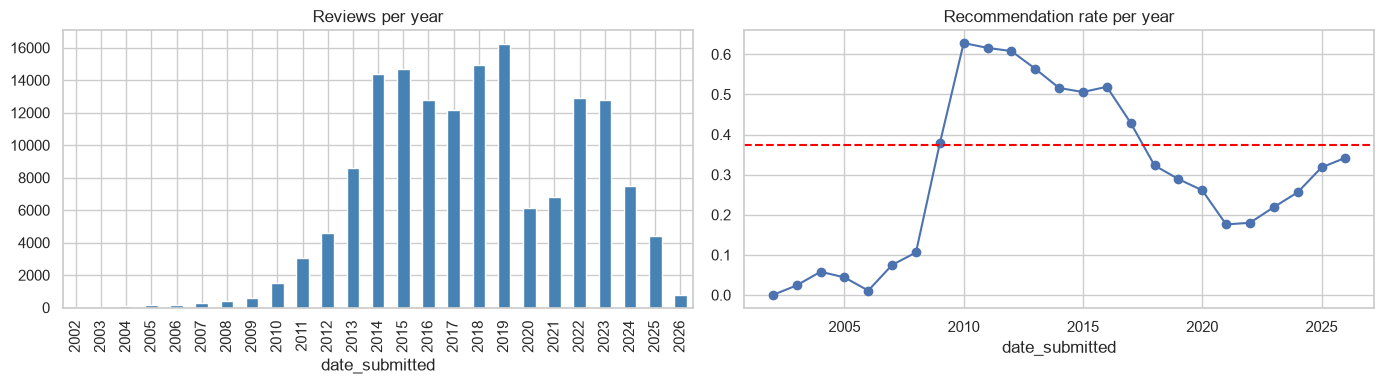

In [20]:
#Reviews and recommendation rate over time
by_year = df_clean.groupby(df_clean["date_submitted"].dt.year).agg(
    n_reviews=("review_id", "size"),
    recommend_rate=("recommended", "mean"),
).round(3)
display(by_year)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
by_year["n_reviews"].plot(kind="bar", ax=axes[0], color="steelblue", title="Reviews per year")
by_year["recommend_rate"].plot(ax=axes[1], marker="o", title="Recommendation rate per year")
axes[1].axhline(df_clean["recommended"].mean(), color="red", linestyle="--")
plt.tight_layout()
plt.show()

In [21]:
#Seat class and treveller type
for col in ["seat_type", "type_of_traveller"]:
    display(
        df_clean.groupby(col, dropna=False)["recommended"]
        .agg(n="size", recommend_rate="mean")
        .round(3)
        .sort_values("n", ascending=False)
    )

df_clean["nationality_grouped"].value_counts().head(10)


,n,recommend_rate
seat_type,,
Economy Class,124735,0.339
Business Class,19180,0.604
Premium Economy,6096,0.403
First Class,3208,0.523
NaN,2856,0.198


,n,recommend_rate
type_of_traveller,,
Solo Leisure,42334,0.377
NaN,39208,0.535
Couple Leisure,30370,0.294
Family Leisure,26320,0.270
Business,17843,0.311


nationality_grouped
United States     51211
United Kingdom    24933
Australia         13415
Canada            12752
Germany            4240
India              3702
Singapore          2420
Netherlands        2297
France             2125
New Zealand        1781
Name: count, dtype: int64

,1.0,2.0,3.0,4.0,5.0
seat_comfort,0.32,0.15,0.19,0.20,0.15
cabin_staff_service,0.30,0.12,0.15,0.17,0.26
food_and_beverages,0.34,0.14,0.18,0.18,0.16
inflight_entertainment,0.38,0.12,0.17,0.18,0.15
ground_service,0.50,0.09,0.10,0.13,0.17
wifi_and_connectivity,0.61,0.09,0.10,0.09,0.11
value_for_money,0.42,0.12,0.11,0.16,0.19


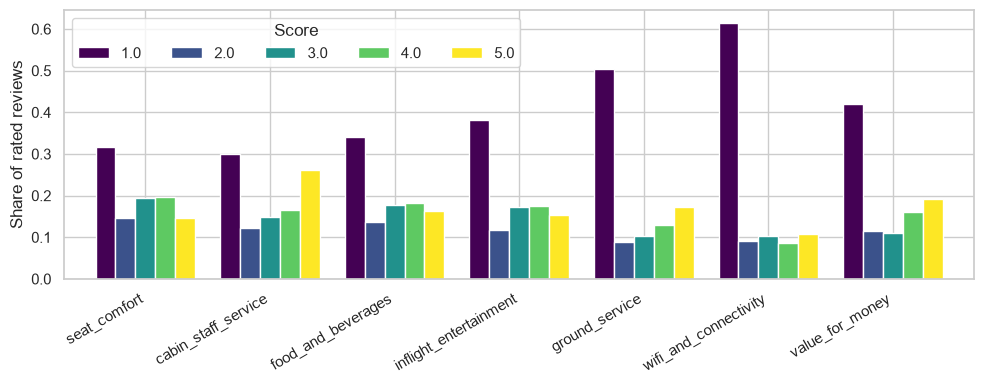

In [22]:
#Rating distributions
dist = df_clean[rating_cols].apply(pd.Series.value_counts, normalize=True).T
display(dist.round(2))

ax = dist.plot(kind="bar", figsize=(10, 4), width=0.8, colormap="viridis")
ax.set_ylabel("Share of rated reviews")
ax.set_xlabel("")
ax.legend(title="Score", ncol=5)
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

#### Section 3 notes

- **37.5%** of reviews recommend the airline, which is the baseline for later comparisons.
- Review volume peaked in 2014 to 2019, dropped in 2020 and 2021, and has fallen again since 2024.
- The recommendation rate fell from **62.8%** (2010) to **17.6%** (2021), then partly recovered. Years before 2009 have too few reviews to trust.
- The verified label only exists from 2017. The lower overall rate for verified reviews comes from the mix of years, not from verification itself.
- Business Class recommends far more (**60.4%**) than Economy (**33.9%**), and Economy is about 80% of all reviews.
- Score 1 is the most common score in every rating column.


### 4. Airline comparison


In [23]:
#Reviews per airline
per_airline = df_clean.groupby("airline_id").agg(
    n_reviews=("review_id", "size"),
    recommend_rate=("recommended", "mean"),
)

per_airline["n_reviews"].describe().round(1)

count     580.0
mean      269.1
std       686.7
min         1.0
25%         6.0
50%        32.5
75%       178.0
max      6717.0
Name: n_reviews, dtype: float64

In [24]:
#Sample size threshold
rows = []
for t in (30, 50, 100, 200):
    sub = per_airline[per_airline["n_reviews"] >= t]
    rows.append({
        "min_reviews": t,
        "airlines": len(sub),
        "share_of_reviews": round(sub["n_reviews"].sum() / len(df_clean), 3),
    })
pd.DataFrame(rows)


,min_reviews,airlines,share_of_reviews
0,30,300,0.983
1,50,250,0.971
2,100,185,0.941
3,200,140,0.903


In [25]:
#Recommendation rate per airline
MIN_REVIEWS = 100
ranked = per_airline[per_airline["n_reviews"] >= MIN_REVIEWS].copy()
ranked["recommend_rate"] = ranked["recommend_rate"].round(3)

ranked["recommend_rate"].describe()

count    185.000000
mean       0.408800
std        0.180548
min        0.072000
25%        0.275000
50%        0.392000
75%        0.500000
max        0.867000
Name: recommend_rate, dtype: float64

In [26]:
#Top and bottom 10 airlines
airlines = pd.read_csv("../../Data/raw/airlines.csv", encoding="utf-8-sig")
ranked = ranked.reset_index().merge(airlines, on="airline_id", how="left")

cols = ["airline_name", "n_reviews", "recommend_rate"]
display(ranked.sort_values("recommend_rate", ascending=False).head(10)[cols])
display(ranked.sort_values("recommend_rate").head(10)[cols])

,airline_name,n_reviews,recommend_rate
73,Garuda Indonesia,977,0.867
50,China Southern Airlines,2058,0.862
79,Hainan Airlines,426,0.854
31,Asiana Airlines,527,0.814
58,EVA Air,673,0.807
0,ANA All Nippon Airways,626,0.799
7,Air Astana,252,0.790
175,Volotea,718,0.769
87,Japan Airlines,350,0.763
57,Dragonair,173,0.763


,airline_name,n_reviews,recommend_rate
72,Frontier Airlines,3832,0.072
75,Go First,191,0.079
173,VivaAerobús,155,0.090
138,Silver Airways,220,0.091
174,Volaris,421,0.114
86,Interjet,214,0.126
145,Spirit Airlines,5285,0.132
29,American Airlines,6354,0.139
82,ITA Airways,277,0.152
69,Flair Airlines,1189,0.155


In [27]:
year_med = (
    df_clean.assign(year=df_clean["date_submitted"].dt.year)
    .groupby("airline_id")["year"].median()
    .rename("median_year")
)
ranked = ranked.merge(year_med, on="airline_id", how="left")

cols = ["airline_name", "n_reviews", "recommend_rate", "median_year"]
display(ranked.sort_values("recommend_rate", ascending=False).head(10)[cols])
display(ranked.sort_values("recommend_rate").head(10)[cols])

,airline_name,n_reviews,recommend_rate,median_year
73,Garuda Indonesia,977,0.867,2016.0
50,China Southern Airlines,2058,0.862,2017.0
79,Hainan Airlines,426,0.854,2017.0
31,Asiana Airlines,527,0.814,2014.0
58,EVA Air,673,0.807,2016.0
0,ANA All Nippon Airways,626,0.799,2016.0
7,Air Astana,252,0.790,2016.0
175,Volotea,718,0.769,2024.0
87,Japan Airlines,350,0.763,2015.0
57,Dragonair,173,0.763,2013.0


,airline_name,n_reviews,recommend_rate,median_year
72,Frontier Airlines,3832,0.072,2021.0
75,Go First,191,0.079,2022.0
173,VivaAerobús,155,0.090,2022.0
138,Silver Airways,220,0.091,2022.0
174,Volaris,421,0.114,2020.0
86,Interjet,214,0.126,2019.0
145,Spirit Airlines,5285,0.132,2019.0
29,American Airlines,6354,0.139,2019.0
82,ITA Airways,277,0.152,2023.0
69,Flair Airlines,1189,0.155,2022.0


#### Section 4 notes

- Threshold: 100 reviews per airline (185 airlines, 94.1% of reviews).
- Recommendation rates range from **7.2%** to **86.7%** across airlines, with a median of 39.2%.
- Top: Garuda Indonesia, China Southern, Hainan Airlines. Bottom: Frontier, Go First, VivaAerobús.
- Airlines with later reviews tend to have lower rates, so this ranking partly reflects timing, not only service.


### 5. Ratings vs recommendation


In [28]:
#Ratings vs recommendation
by_rec = df_clean.groupby("recommended")[rating_cols].mean().round(2).T
by_rec["gap"] = (by_rec[1] - by_rec[0]).round(2)
by_rec.sort_values("gap", ascending=True)

recommended,0,1,gap
inflight_entertainment,1.81,3.75,1.94
seat_comfort,1.88,4.03,2.15
wifi_and_connectivity,1.43,3.58,2.15
food_and_beverages,1.74,3.93,2.19
cabin_staff_service,2.03,4.43,2.40
ground_service,1.49,4.16,2.67
value_for_money,1.53,4.33,2.80


#### Section 5 notes

- Reviewers who recommend the airline give much higher ratings in every category (about 3.6 to 4.4) than those who do not (about 1.4 to 2.0).
- The gap is largest for `value_for_money` (**2.80**) and smallest for `inflight_entertainment` (**1.94**).
- Ratings agree with `recommended`, so ratings can be used as a cross-check.
- `wifi_and_connectivity` is rated in far fewer reviews than other categories, so its averages are less reliable.


### 6. Review text profile


In [30]:
#Review length in words
df_clean["n_words"] = df_clean["review"].str.split().str.len()
df_clean.groupby("recommended")["n_words"].describe().round(0)

,count,mean,std,min,25%,50%,75%,max
recommended,,,,,,,,
0,97555.0,152.0,108.0,8.0,79.0,122.0,191.0,1152.0
1,58520.0,113.0,80.0,12.0,59.0,91.0,142.0,822.0


In [32]:
#Most common words
import re
from collections import Counter

stop = set("""the a an and or but to of in on at for with was were is are be been it its i we my our
they their this that as from by not no had have has you me us them so if when then than there which
what who will would could do did does just very also after before up out about into over only all
one two get got""".split())

def top_words(texts, n=25):
    c = Counter()
    for t in texts:
        c.update(w for w in re.findall(r"[a-z']+", t.lower()) if w not in stop and len(w) > 2)
    return c.most_common(n)

sample_0 = df_clean.loc[df_clean["recommended"] == 0, "review"].sample(20000, random_state=42)
top_words(sample_0)

[('flight', 42791),
 ('airline', 11659),
 ('service', 11655),
 ('time', 10956),
 ('hours', 9713),
 ('airport', 8590),
 ('plane', 8112),
 ('again', 7955),
 ('told', 7608),
 ('airlines', 7174),
 ('staff', 7127),
 ('check', 7036),
 ('customer', 6975),
 ('seats', 6857),
 ('never', 6780),
 ('even', 6773),
 ('seat', 6711),
 ('flights', 6655),
 ('back', 6577),
 ('fly', 6573),
 ('because', 6284),
 ('delayed', 6047),
 ('hour', 5859),
 ('other', 5555),
 ('any', 5437)]

In [35]:
#Candidate incident keywords
keywords = {
    "delay": r"delay",
    "cancellation": r"cancel",
    "baggage": r"baggage|luggage|suitcase|\bbags?\b",
    "lost or damaged": r"lost|damaged|missing",
    "refund or compensation": r"refund|compensat",
    "customer service": r"customer service|call cent(?:re|er)",
    "rude staff": r"rude|unhelpful|attitude|unprofessional",
    "food": r"food|meal|catering",
    "seat": r"seat|legroom",
}

rows = []
for name, pattern in keywords.items():
    hit = df_clean["review"].str.contains(pattern, case=False, regex=True)
    rows.append({
        "keyword": name,
        "not_recommended": hit[df_clean["recommended"] == 0].mean(),
        "recommended": hit[df_clean["recommended"] == 1].mean(),
    })
(pd.DataFrame(rows).set_index("keyword") * 100).round(1)

,not_recommended,recommended
keyword,,
delay,30.4,13.9
cancellation,20.2,3.0
baggage,30.0,21.5
lost or damaged,10.8,2.4
refund or compensation,16.1,1.5
customer service,20.5,3.8
rude staff,17.9,3.2
food,25.6,55.4
seat,35.1,54.5


In [36]:
#Sample of non-recommending reviews
sample = df_clean[df_clean["recommended"] == 0].sample(30, random_state=1)
for i, text in enumerate(sample["review"], 1):
    print(f"{i}. {text[:400]}\n")

1. Website is poor and online checkin never seems to work. Flight was full but boarding handled well and departure from AUH was on time. Meal service was average - behind the standards of EK, EY etc. Royal Jordanian has started charging for drinks in economy which is stingy. Meal trays cleared quickly then crew disappear for the rest of the 3 hour flight. Connecting flight Amman to Cairo delayed with

2. Worst airline so far I've traveled, cabin crew rude, ground staff don't care - they delay the flight the whole day and then cancel the flight when you have no choice left. A clear weather issue, some time they have no cabin crew or captains. They work like the really don't care what their passengers are going through. Simply don't have any words to express here. Good luck Delta - will see you guys

3. Dakar to Prague via Istanbul. They changed our flight and we had to wait 10 hours at the airport. Via email they promised Istanbul tour but at the airport we have been told that tour star

#### Section 6 notes

- Reviews that do not recommend are longer (median **122** words) than those that do (**91**).
- Common words are generic (flight, airline, service, time), so word counts alone do not reveal incident types.
- Cancellation, refund, customer service, rude staff and lost or damaged items are mentioned far more in non-recommending reviews, so they are candidates for the incident list.
- Mentioning food or seats is more common in recommending reviews, so a keyword match does not mean a complaint.


### 7. Key findings

#### What the data shows

- (from section 3) Recommendation rate and its trend over time.
- (from section 4) Range across airlines, and which are at both ends.
- (from section 5) Ratings agree with `recommended`.
- (from section 6) Main complaint themes in non-recommending reviews.

#### Data limitations

- Reviews before 2009 are too few to trust.
- The verified label only exists from 2017.
- Rankings over all years partly reflect timing.
- 6,986 review texts appear under more than one airline (kept).
